# Check Peaks Results Summary

Summarise `data/zooniverse/check_peaks_results.csv`, including agreement/vote count distributions and requested plots.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
CSV_PATH = Path("data/zooniverse/check_peaks_results.csv")
AGREEMENT_COL = "data.agreement"
NUM_VOTES_COL = "data.num_votes"
MOST_LIKELY_COL = "data.most_likely"

In [3]:
results = pd.read_csv(CSV_PATH)

results[AGREEMENT_COL] = pd.to_numeric(results[AGREEMENT_COL], errors="coerce")
results[NUM_VOTES_COL] = pd.to_numeric(results[NUM_VOTES_COL], errors="coerce")

display(results.head())

,id,reducer_key,workflow_id,subject_id,created_at,updated_at,subgroup,lock_version,reducible_id,reducible_type,data.agreement,data.num_votes,data.most_likely
0,115479595,consensus,31708,119517112,2026-04-21 10:26:21 UTC,2026-04-21 10:26:21 UTC,_default,0,31708,Workflow,1.0,1,0.0
1,115479598,consensus,31708,119628021,2026-04-21 10:26:25 UTC,2026-04-21 20:30:41 UTC,_default,1,31708,Workflow,0.5,1,NaN
2,115479604,consensus,31708,119617362,2026-04-21 10:26:29 UTC,2026-04-21 10:26:29 UTC,_default,0,31708,Workflow,1.0,1,1.0
3,115479620,consensus,31708,119537811,2026-04-21 10:26:37 UTC,2026-04-24 22:57:02 UTC,_default,1,31708,Workflow,0.5,1,1.0
4,115479622,consensus,31708,119591393,2026-04-21 10:26:43 UTC,2026-04-22 18:47:33 UTC,_default,1,31708,Workflow,0.5,1,NaN


## Summary

In [4]:
summary = pd.Series(
    {
        "rows": len(results),
        "subjects": results["subject_id"].nunique() if "subject_id" in results else pd.NA,
        "agreement_min": results[AGREEMENT_COL].min(),
        "agreement_mean": results[AGREEMENT_COL].mean(),
        "agreement_median": results[AGREEMENT_COL].median(),
        "agreement_max": results[AGREEMENT_COL].max(),
        "num_votes_min": results[NUM_VOTES_COL].min(),
        "num_votes_mean": results[NUM_VOTES_COL].mean(),
        "num_votes_median": results[NUM_VOTES_COL].median(),
        "num_votes_max": results[NUM_VOTES_COL].max(),
        "missing_agreement": results[AGREEMENT_COL].isna().sum(),
        "missing_num_votes": results[NUM_VOTES_COL].isna().sum(),
    },
    name="value",
)

display(summary.to_frame())
display(results[[AGREEMENT_COL, NUM_VOTES_COL]].describe().T)

,value
rows,39574.000000
subjects,39574.000000
agreement_min,0.250000
agreement_mean,0.930840
agreement_median,1.000000
agreement_max,1.000000
num_votes_min,1.000000
num_votes_mean,1.114772
num_votes_median,1.000000
num_votes_max,4.000000


,count,mean,std,min,25%,50%,75%,max
data.agreement,39574.0,0.930840,0.171224,0.25,1.0,1.0,1.0,1.0
data.num_votes,39574.0,1.114772,0.346262,1.00,1.0,1.0,1.0,4.0


In [5]:
num_vote_counts = (
    results[NUM_VOTES_COL]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("num_votes")
    .to_frame("rows")
)

display(num_vote_counts)

if MOST_LIKELY_COL in results:
    display(
        results[MOST_LIKELY_COL]
        .fillna("<missing>")
        .astype(str)
        .replace({"": "<blank>"})
        .value_counts()
        .rename_axis(MOST_LIKELY_COL)
        .to_frame("rows")
    )

,rows
num_votes,
1,35370
2,3890
3,290
4,24


,rows
data.most_likely,
1.0,18022
0.0,11142
<missing>,8142
2.0,1607
3.0,661


## Plots

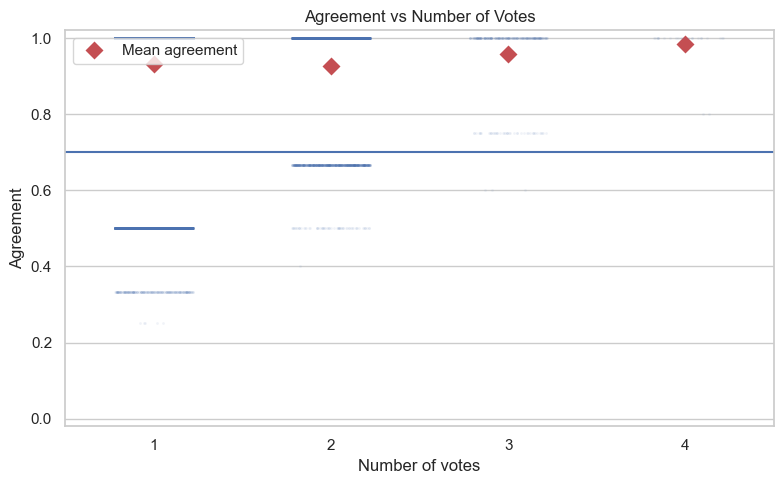

In [10]:
plot_data = results[[NUM_VOTES_COL, AGREEMENT_COL]].dropna().copy()
vote_values = [int(value) for value in sorted(plot_data[NUM_VOTES_COL].astype(int).unique())]
agreement_by_votes = (
    plot_data.groupby(NUM_VOTES_COL, as_index=False)[AGREEMENT_COL]
    .mean()
    .rename(columns={AGREEMENT_COL: "mean_agreement"})
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.stripplot(
    data=plot_data,
    x=NUM_VOTES_COL,
    y=AGREEMENT_COL,
    order=vote_values,
    jitter=0.22,
    alpha=0.08,
    size=2,
    color="C0",
    ax=ax,
)
sns.pointplot(
    data=agreement_by_votes,
    x=NUM_VOTES_COL,
    y="mean_agreement",
    order=vote_values,
    color="C3",
    errorbar=None,
    markers="D",
    linestyles="none",
    label="Mean agreement",
    ax=ax,
)

plt.axhline(0.7)
ax.set_title("Agreement vs Number of Votes")
ax.set_xlabel("Number of votes")
ax.set_ylabel("Agreement")
ax.set_ylim(-0.02, 1.02)
ax.set_xticks(range(len(vote_values)))
ax.set_xticklabels(vote_values)
ax.legend()

plt.tight_layout()

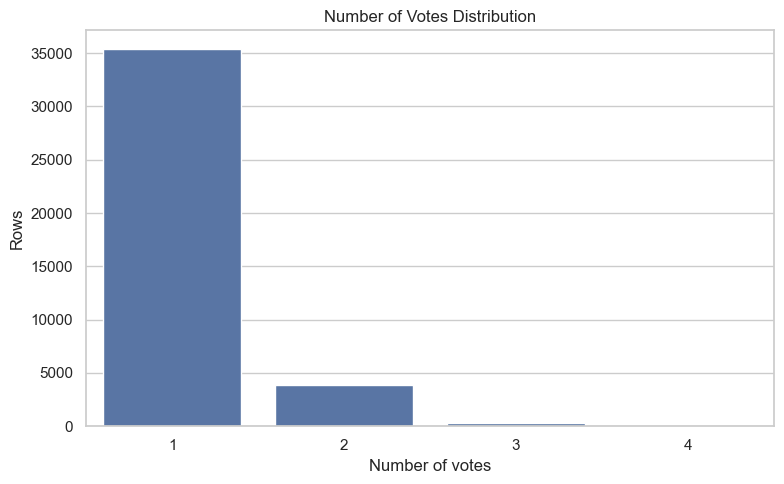

In [7]:
vote_values = [int(value) for value in sorted(results[NUM_VOTES_COL].dropna().astype(int).unique())]

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=results.dropna(subset=[NUM_VOTES_COL]),
    x=NUM_VOTES_COL,
    order=vote_values,
    color="C0",
    ax=ax,
)

ax.set_title("Number of Votes Distribution")
ax.set_xlabel("Number of votes")
ax.set_ylabel("Rows")

plt.tight_layout()